# B-6511502A · quais sensores o modelo precisa?

Um equipamento mais quente não é, sozinho, sinal de falha. Aqui comparamos o modelo atual (14 sensores) com versões
sem a temperatura, sem a temperatura e o deslocamento axial, e só com as vibrações. Todas treinadas até jan/2023 e
testadas em fev–mai/2023 (que nenhuma viu), com a falha real de 15/05/2023 e duas mudanças simuladas a partir de
01/02/2023: **temperatura do mancal +8 °C** (não deveria alertar) e **vibrações ×1,3** (alertar é o esperado).
12 modelos por variante (grade do retreino).

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "scripts")); sys.path.insert(0, str(RAIZ / "src"))
import subconjuntos_b6511502a as sb
ds = sb.ds
R = RAIZ / "results/subconjuntos_b6511502a"
av = pd.read_csv(R / "avaliacao.csv")
raw = ds.load_equipment_data(ds.EQ)
NOMES = {"atual": "atual (14 sensores)", "sem_temp": "sem temperatura (13)", "sem_temp_axial": "sem temperatura e axial (11)",
         "so_vib": "só vibrações (8)"}
CORES = {"atual": "#8a897f", "sem_temp": "#eb6834", "sem_temp_axial": "#1baf7a", "so_vib": "#2a78d6"}
VERMELHO, SERIE, TEXTO = "#e5484d", "#6f9fd1", "#52514e"
plt.rcParams.update({"font.size": 11})
def estilo(ax, t=None):
    if t: ax.set_title(t, loc="left", fontsize=12, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)

## 1. Onde a falha aparece

Quanto cada sensor mudou no dia da falha (13/05/2023), em desvios-padrão da operação normal (nov/22–mai/23).

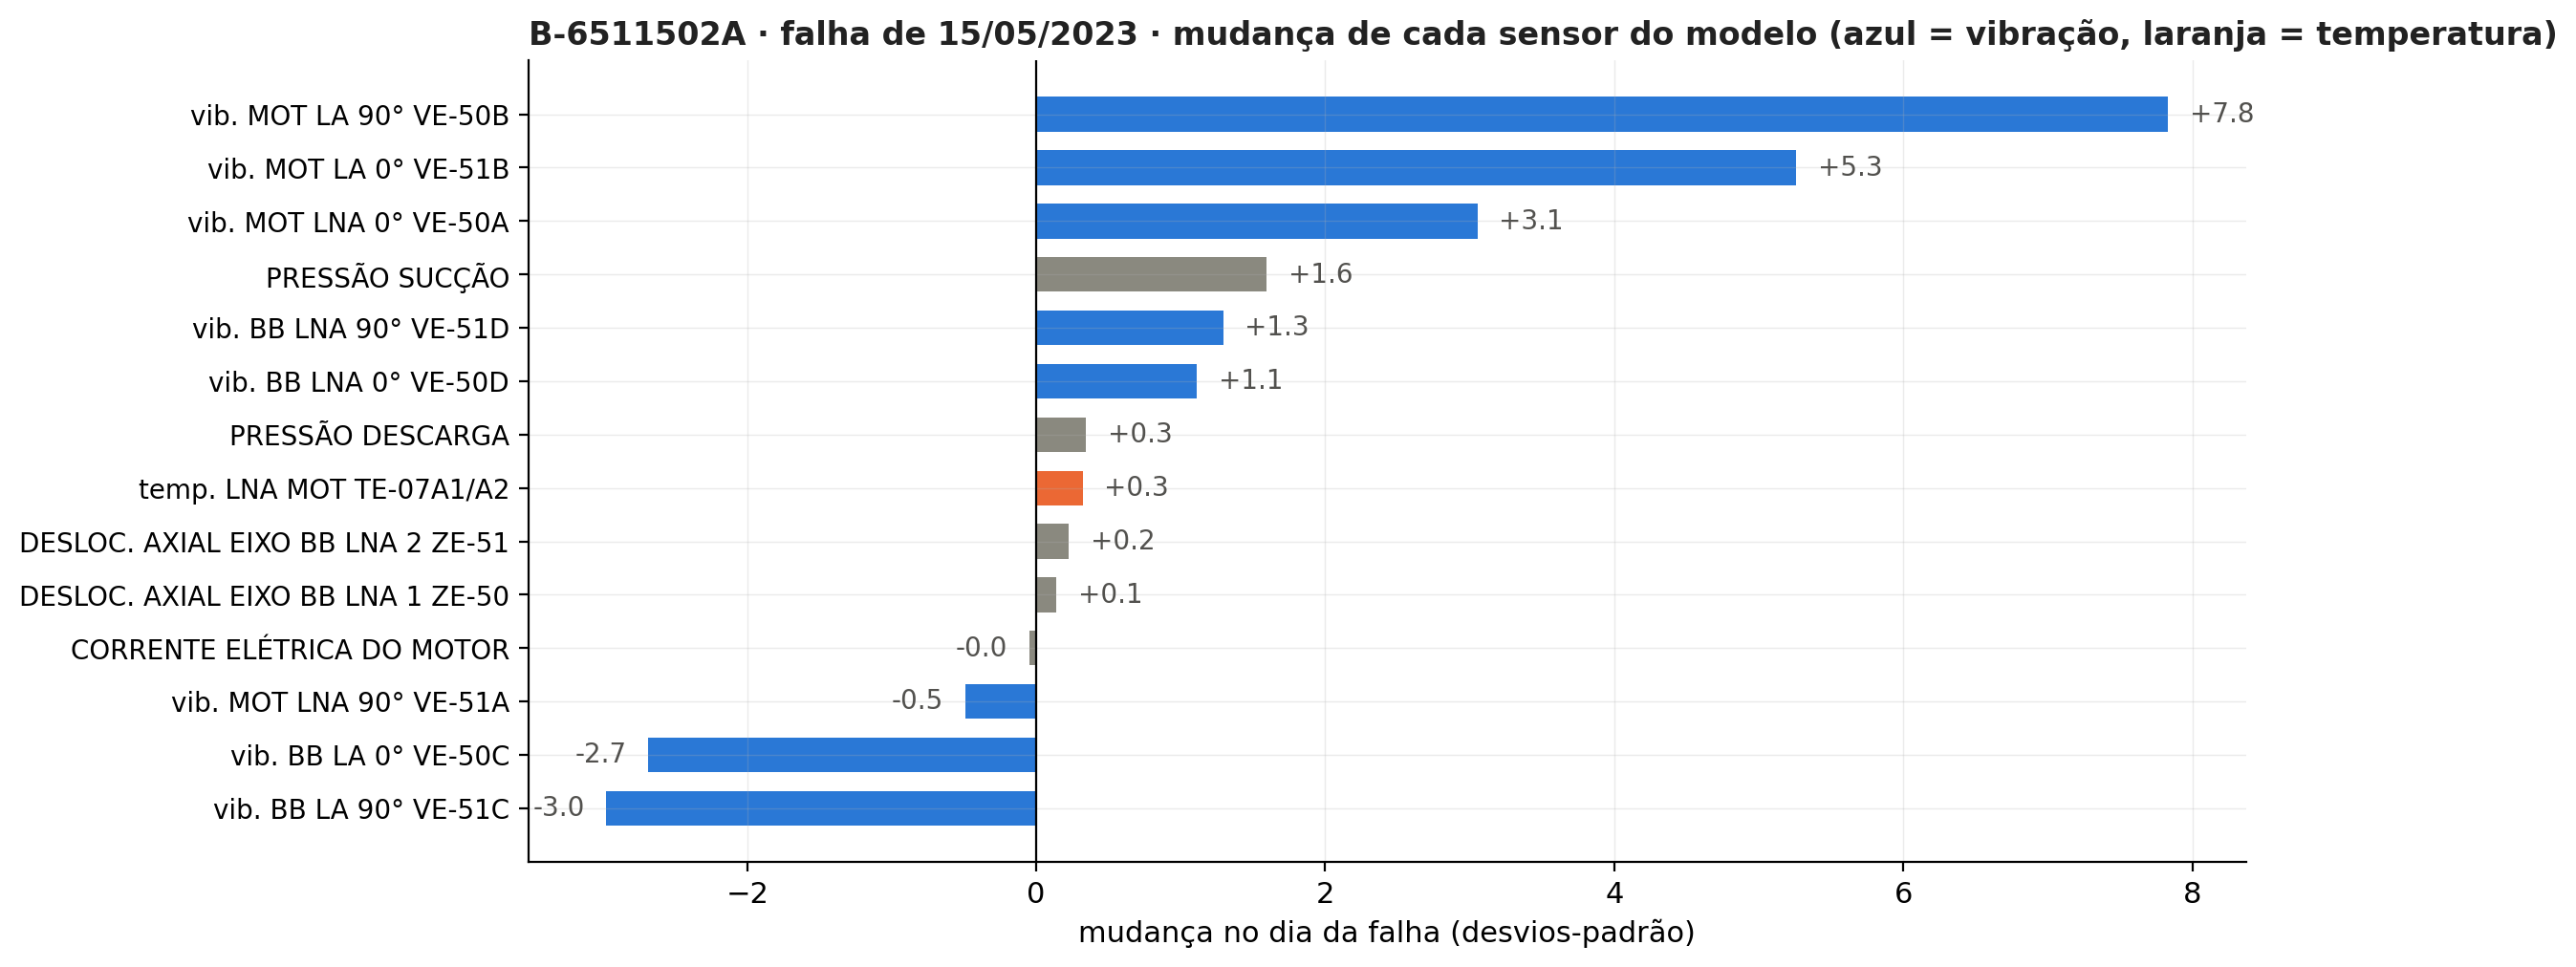

In [2]:
op = raw[raw[ds.CORR] > 60]
norm, fal = op["2022-11-01":"2023-05-05"], op["2023-05-13":"2023-05-15"]
z = ((fal.median() - norm.median()) / norm.std())[ds.CFG.pre_split_steps[-1]["features"]].sort_values()
cor = ["#2a78d6" if c.startswith("VIB") else "#eb6834" if c.startswith("TEMP") else "#8a897f" for c in z.index]
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.barh(range(len(z)), z.values, color=cor, height=0.65)
for i, v in enumerate(z.values):
    ax.text(v + (0.15 if v >= 0 else -0.15), i, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=10, color=TEXTO)
ax.set_yticks(range(len(z)), [c.replace("VIB. MANCAL RADIAL ", "vib. ").replace("TEMP. MANCAL ", "temp. ") for c in z.index], fontsize=10)
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("mudança no dia da falha (desvios-padrão)")
estilo(ax, "B-6511502A · falha de 15/05/2023 · mudança de cada sensor do modelo (azul = vibração, laranja = temperatura)")
fig.tight_layout()

**Leitura:** a falha é a vibração do mancal LA do motor (VE-50B +7,8 e VE-51B +5,3 desvios). A temperatura que o
modelo usa (TE-07A) mudou +0,3 — nada. Ela só entra no modelo como fonte de alarme quando o mancal esquenta por outro motivo.

## 2. As quatro variantes, modelo a modelo

Cada ponto é um dos 12 modelos de cada variante.

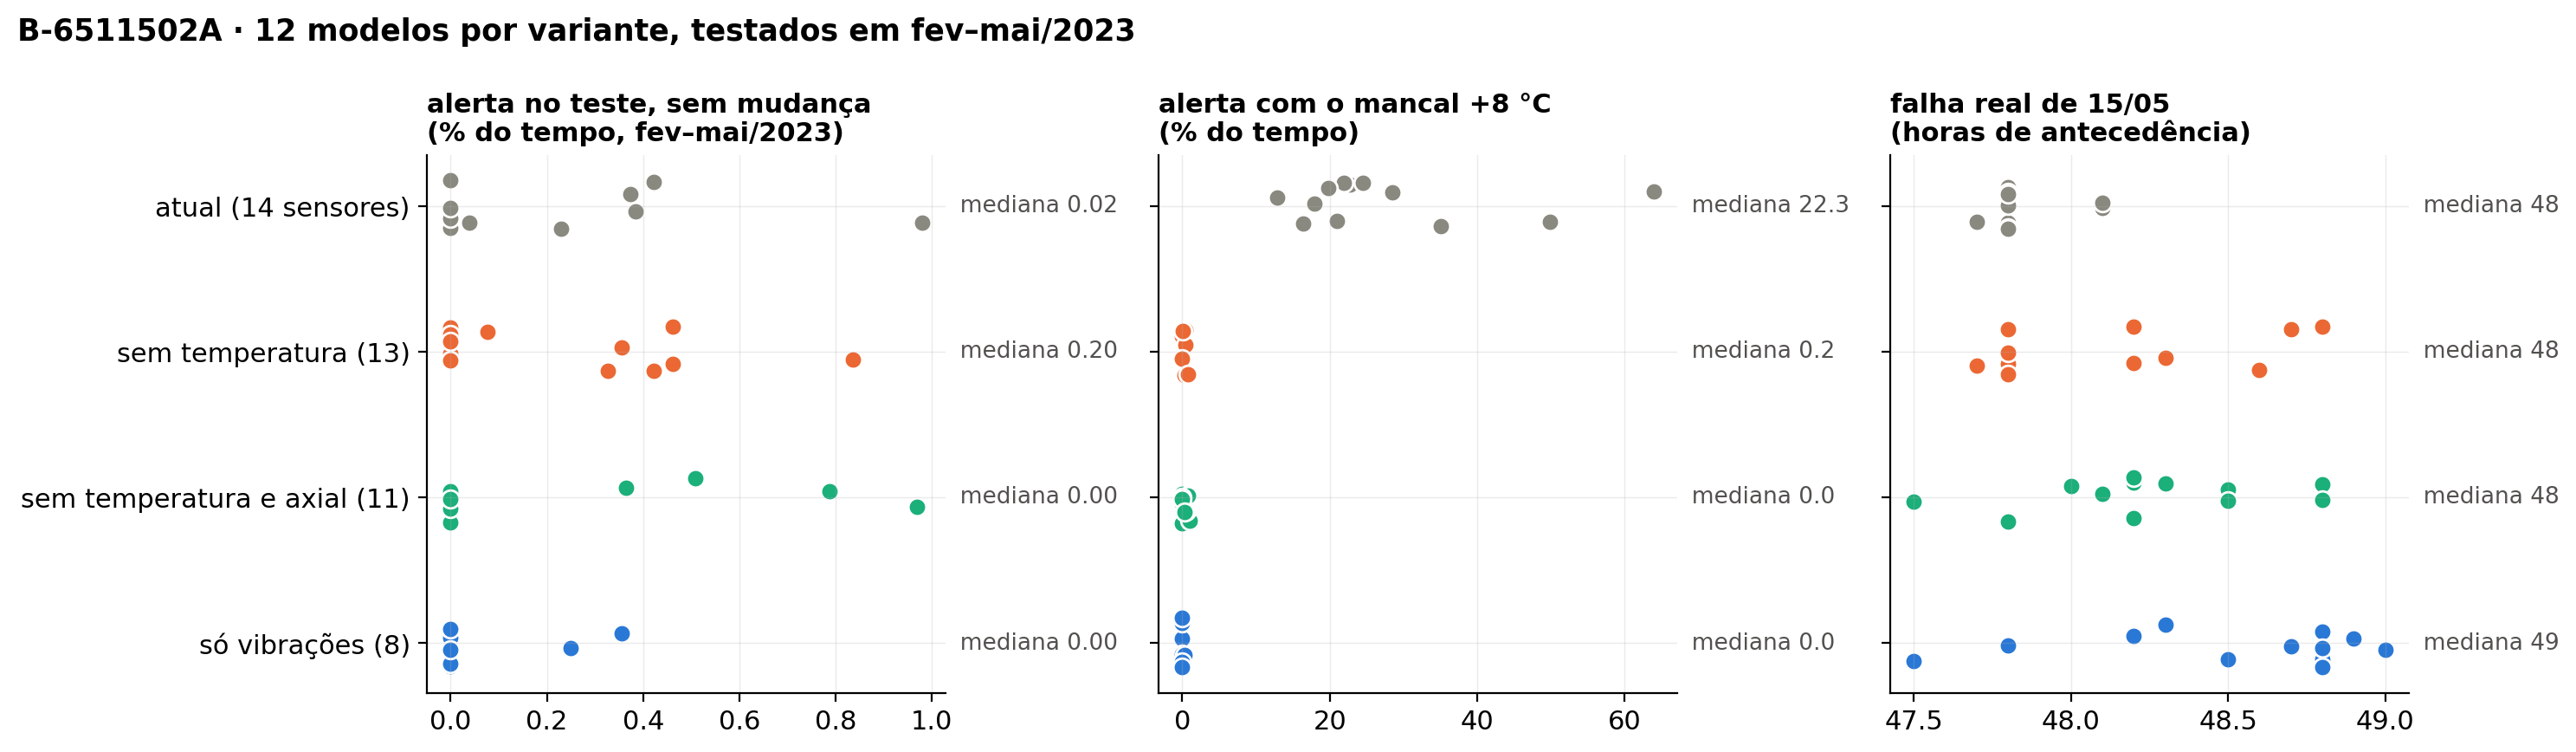

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
ordem = list(NOMES)
rng = np.random.default_rng(0)
for ax, (col, tit, fmt) in zip(axes, [("real_alerta_%", "alerta no teste, sem mudança\n(% do tempo, fev–mai/2023)", "{:.2f}"),
                                      ("temperatura_alerta_%", "alerta com o mancal +8 °C\n(% do tempo)", "{:.1f}"),
                                      ("real_falha_h", "falha real de 15/05\n(horas de antecedência)", "{:.0f}")]):
    for i, v in enumerate(ordem):
        d = av[av.variante == v][col]
        ax.scatter(d.fillna(-5), i + rng.uniform(-0.18, 0.18, len(d)), color=CORES[v], s=55, edgecolor="white", lw=1)
        ax.text(1.0, i, "  mediana " + (fmt.format(d.median()) if d.notna().any() else "—"), transform=ax.get_yaxis_transform(),
                va="center", fontsize=9.5, color=TEXTO)
    ax.set_title(tit, loc="left", fontsize=11, fontweight="bold"); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)
axes[0].set_yticks(range(len(ordem)), [NOMES[v] for v in ordem]); axes[0].invert_yaxis()
fig.suptitle("B-6511502A · 12 modelos por variante, testados em fev–mai/2023", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout()

In [4]:
t = av.groupby("variante").agg(**{
    "alerta sem mudança (%)": ("real_alerta_%", "median"), "alerta com +8 °C (%)": ("temperatura_alerta_%", "median"),
    "pior modelo com +8 °C (%)": ("temperatura_alerta_%", "max"), "alerta com vibração ×1,3 (%)": ("vibracao_alerta_%", "median"),
    "detectam a falha": ("real_falha_h", lambda s: f"{s.notna().sum()}/12"), "antecedência (h)": ("real_falha_h", "median")}).reindex(ordem)
t.index = [NOMES[v] for v in t.index]; t.round(2)

,alerta sem mudança (%),alerta com +8 °C (%),pior modelo com +8 °C (%),"alerta com vibração ×1,3 (%)",detectam a falha,antecedência (h)
atual (14 sensores),0.02,22.34,63.91,84.81,12/12,47.80
sem temperatura (13),0.20,0.20,0.84,86.66,12/12,48.00
sem temperatura e axial (11),0.00,0.00,0.97,86.65,12/12,48.20
só vibrações (8),0.00,0.00,0.36,84.98,12/12,48.75


## 3. O mancal 8 °C mais quente: o modelo atual × o sem temperatura

Temperatura TE-07A (com +8 °C a partir de 01/02/2023) e a vibração VE-50B, com os alertas de um modelo de cada variante.

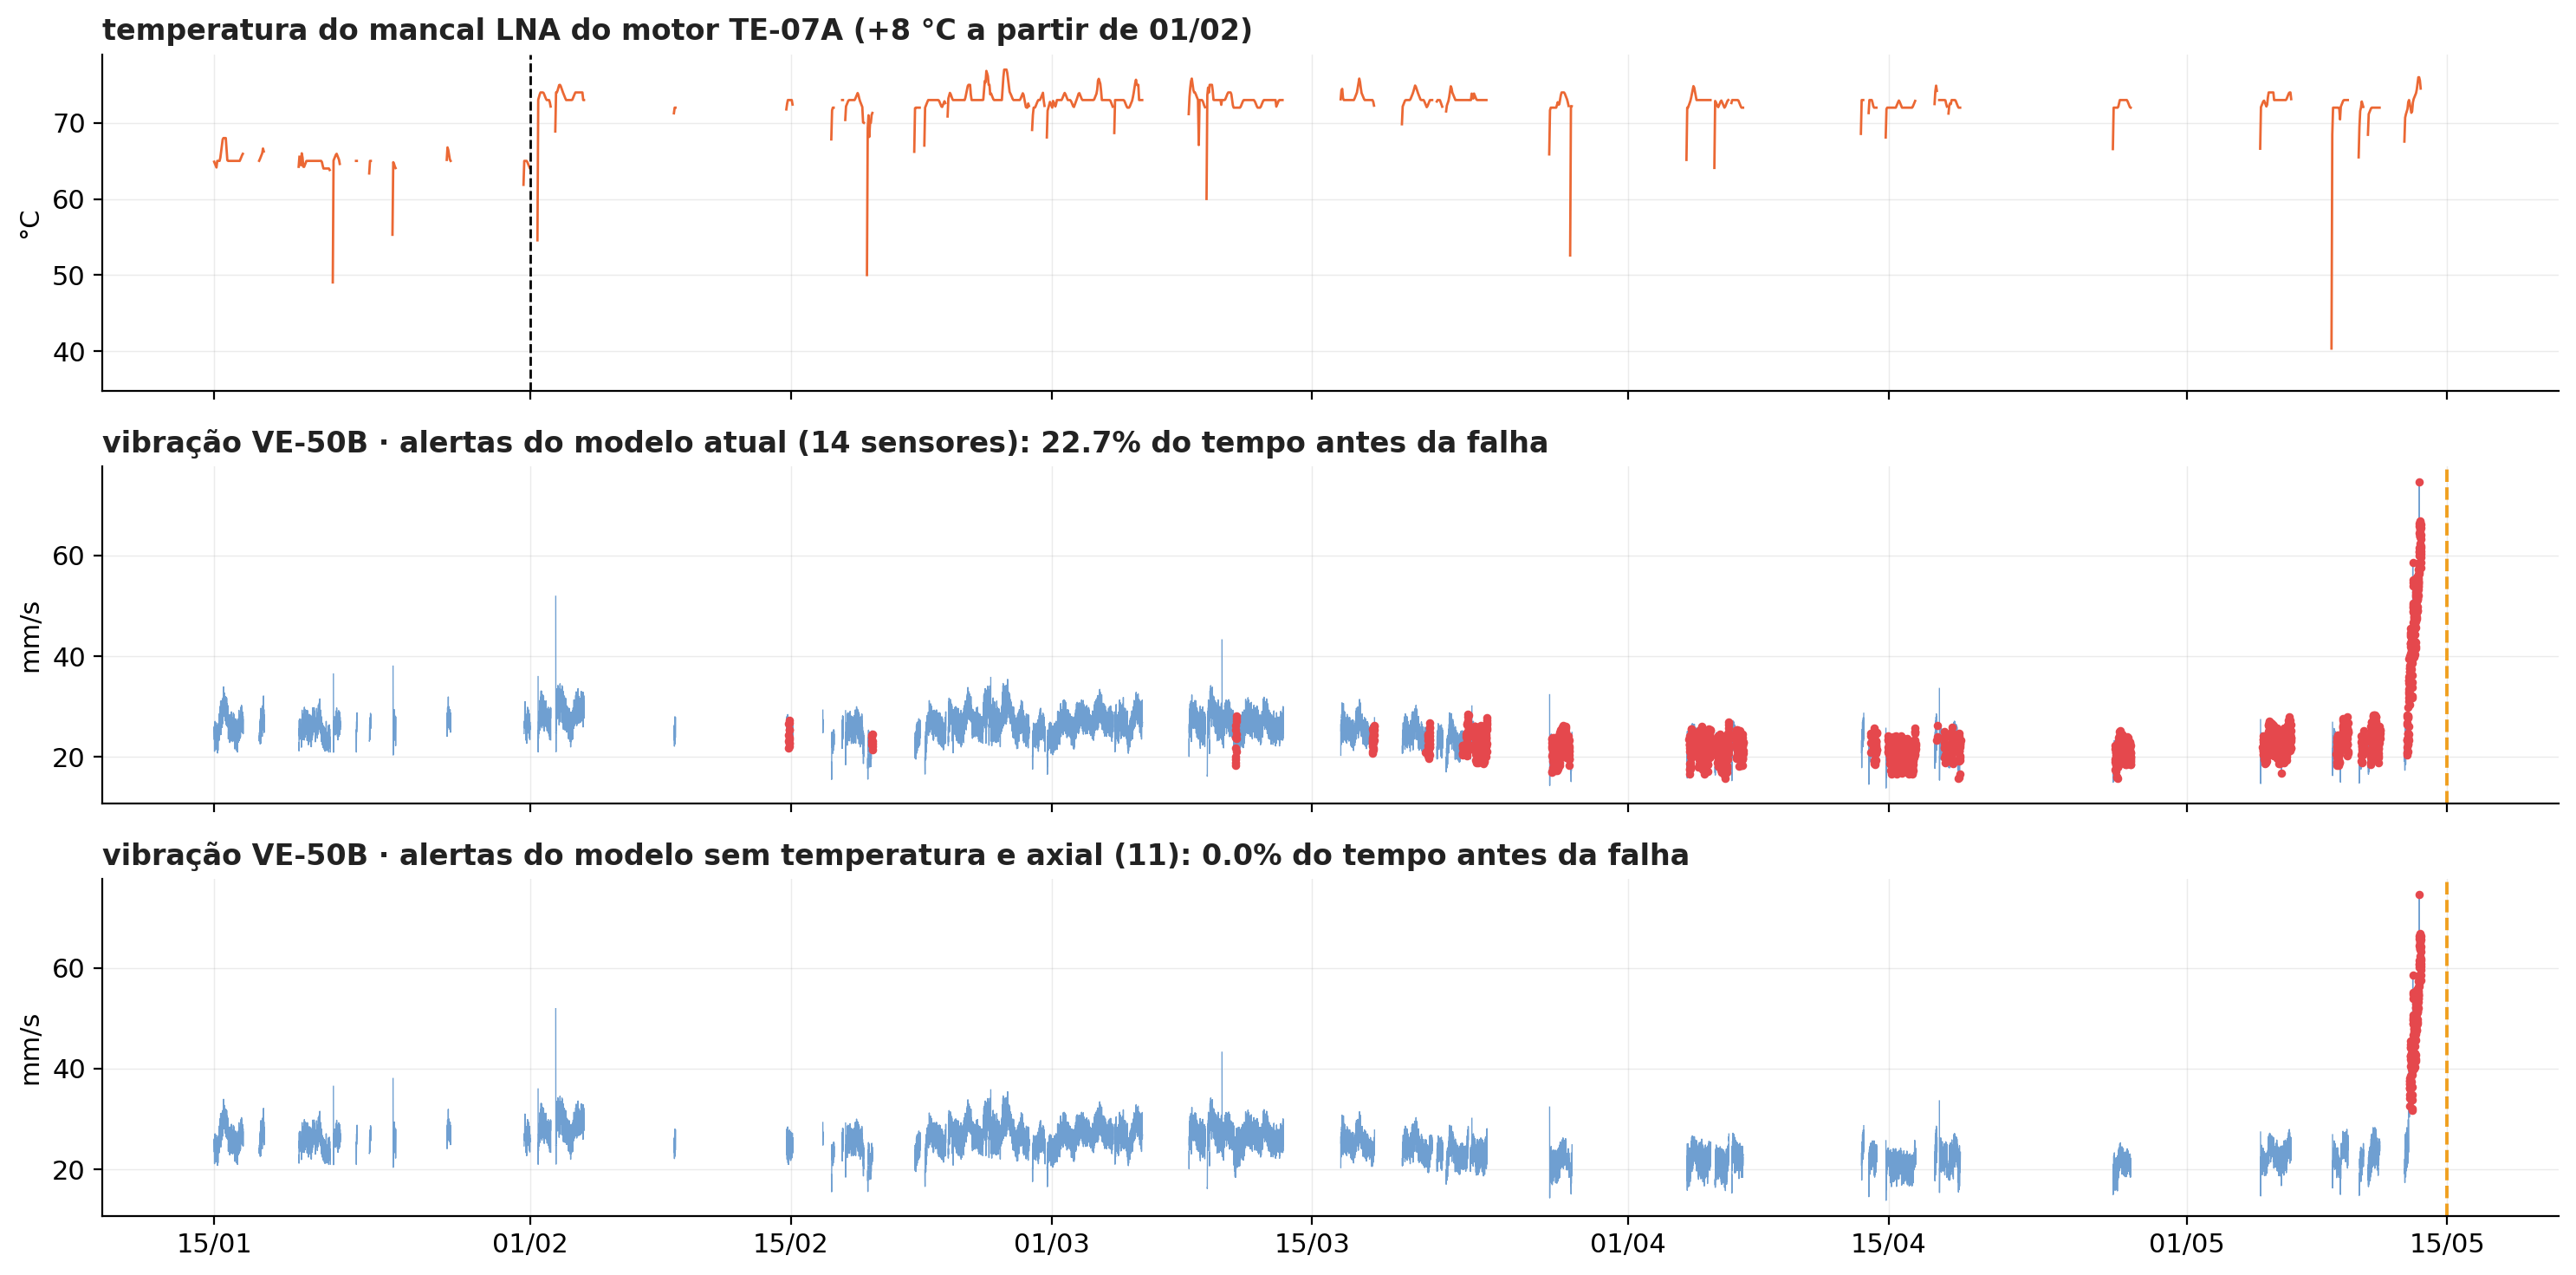

In [5]:
tag = "l128-64-32_lat16_lr0.0001_s0"
quente = sb.aplicar(raw, sb.CENARIOS["temperatura"])
ini, fim = "2023-01-15", "2023-05-14"
fig, axes = plt.subplots(3, 1, figsize=(15, 7.5), sharex=True)
t = quente[sb.TEMP].where(quente[ds.CORR] > 60).loc[ini:fim].resample("1h").median()
axes[0].plot(t.index, t.values, color="#eb6834", lw=1); axes[0].axvline(sb.TE, color="black", ls="--", lw=1)
axes[0].set_ylabel("°C"); estilo(axes[0], "temperatura do mancal LNA do motor TE-07A (+8 °C a partir de 01/02)")
v = quente["VIB. MANCAL RADIAL MOT LA 90° VE-50B"].where(quente[ds.CORR] > 60).loc[ini:fim]
for ax, var in zip(axes[1:], ["atual", "sem_temp_axial"]):
    a = ds.alerta(R / var / tag, quente).loc[ini:fim]
    ax.plot(v.index, v.values, color=SERIE, lw=0.5)
    p = v.reindex(a.index)[a]; ax.scatter(p.index, p.values, color=VERMELHO, s=6, zorder=3)
    ax.axvline(ds.FALHA, color="#f0a020", ls="--", lw=1.4); ax.set_ylabel("mm/s")
    estilo(ax, f"vibração VE-50B · alertas do modelo {NOMES[var]}: {100 * a.loc['2023-02-01':'2023-05-08'].mean():.1f}% do tempo antes da falha")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout()

## 4. A falha real, com e sem a temperatura no modelo

Os 10 dias antes da falha, dado real (sem mudança).

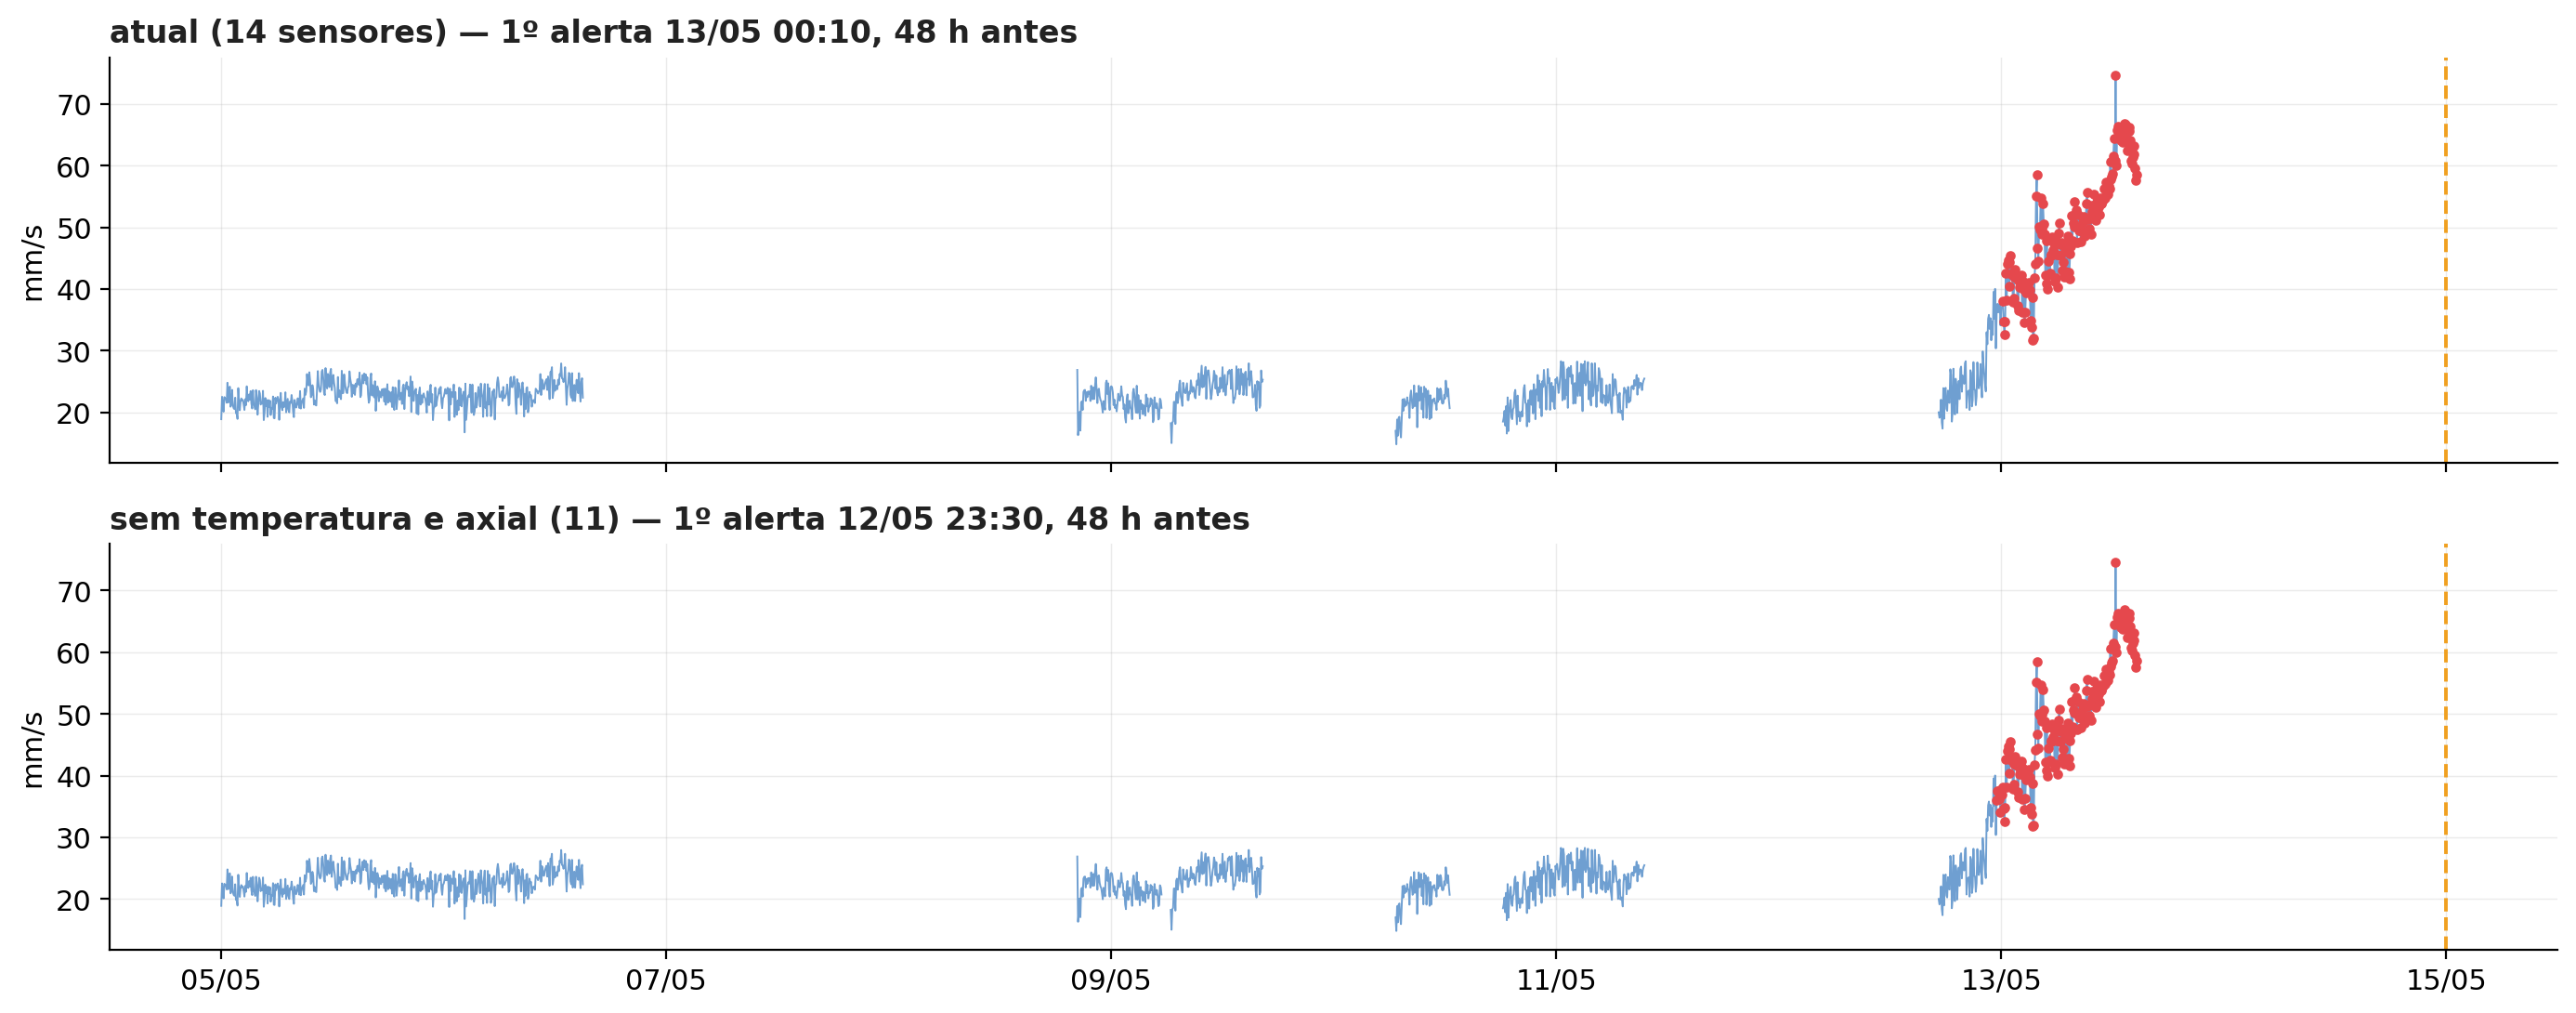

In [6]:
ini = ds.FALHA - pd.Timedelta(days=10)
v = raw["VIB. MANCAL RADIAL MOT LA 90° VE-50B"].where(raw[ds.CORR] > 60).loc[ini:ds.FALHA]
fig, axes = plt.subplots(2, 1, figsize=(14, 5.6), sharex=True)
for ax, var in zip(axes, ["atual", "sem_temp_axial"]):
    a = pd.read_parquet(R / var / tag / "alerta_real.parquet").iloc[:, 0].astype(bool).loc[ini:ds.FALHA]
    ax.plot(v.index, v.values, color=SERIE, lw=0.7)
    p = v.reindex(a.index)[a]; ax.scatter(p.index, p.values, color=VERMELHO, s=8, zorder=3)
    ax.axvline(ds.FALHA, color="#f0a020", ls="--", lw=1.4)
    t1 = a[a].index.min() if a.any() else None
    estilo(ax, f"{NOMES[var]} — " + (f"1º alerta {t1:%d/%m %H:%M}, {(ds.FALHA - t1).total_seconds() / 3600:.0f} h antes" if t1 is not None else "não alerta"))
    ax.set_ylabel("mm/s")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout()

## Conclusões

- **Tirar a temperatura não custa nada na falha:** as quatro variantes detectam a falha real nos 12 modelos, ~48 h antes
  (o máximo que o dado permite: o sinal aparece no último dia).
- **E protege contra o "equipamento mais quente":** com o mancal +8 °C, o modelo atual fica ~22% do tempo em alerta
  (até 64% no pior modelo); sem a temperatura, praticamente zero.
- **Tirar também o deslocamento axial** (ou ficar só com as vibrações) deixa o período normal com 0% de alerta.
  Entre "sem temperatura e axial" (mantém corrente e pressões como contexto de operação) e "só vibrações" o resultado é
  igual; a primeira é a recomendada, pela lição do B-8802B (as pressões ajudam o modelo a saber o regime).
- **Vibração 30% maior faz todos alertarem** (~85% do tempo): é o comportamento certo — vibração alta é o que antecede a
  falha neste equipamento. Se a operação disser que um patamar novo de vibração é normal (ex.: depois de um reparo), é o
  caso do retreino.
- **Engenharia de features:** não precisou. O ganho veio de escolher os sensores certos; a temperatura continua vigiada
  por fora (monitor de temperatura M8).